# Deep Learning
## Practical Deep Learning Tutorial with PyTorch - Tutorial N° 1

### 2025-2026

# Importing necessary libraries

In [20]:
import torch
import torch.nn as nn
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.pyplot import plot, title, axis

# Useful Functions

You will need these 3 functions for this tutorial :

`set_default` to customize figure layouts.

`show_scatterplot` draws a point cloud $X$ in 2-D, each data point has a specific color.

`plot_bases` shows an arrow along the x-axis in red and an arrow along the y-axis in green.

**Warning:** these functions expect tensors stored on the **CPU**.

In [21]:
def set_default(figsize=(10, 10), dpi=100):
    plt.style.use(['dark_background', 'bmh'])
    plt.rc('axes', facecolor='k')
    plt.rc('figure', facecolor='k')
    plt.rc('figure', figsize=figsize, dpi=dpi)

def show_scatterplot(X, title=''):
    plt.figure()
    x_min=-1.5
    x_max=1.5
    colors = (X-x_min)/(x_max-x_min)
    colors = (colors * 511).short().numpy()
    colors = np.clip(colors, 0, 511)
    colors= colors[:, 0]
    plt.scatter(X[:, 0], X[:, 1], c=colors, s=30,cmap='plasma')
    plt.title(title)
    plt.axis('off')

def plot_bases(bases, width=0.04):
    plt.arrow(*bases[0], *bases[2], width=width, color=(1,0,0), zorder=10, alpha=1., length_includes_head=True)
    plt.arrow(*bases[1], *bases[3], width=width, color=(0,1,0), zorder=10, alpha=1., length_includes_head=True)

In [22]:
set_default()

PyTorch can run on both the CPU and GPU of a computer.

The CPU is useful for sequential tasks, while the GPU is useful for parallel tasks.

You have to make sure your tensors and models are transferred to the device’s memory. This can be done with the following line of code:

In [23]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

This line creates a variable, called device, that is assigned to the GPU if one is available; otherwise, it defaults to the CPU.

# Data Generation

1. Create a tensor $X$ of 1000 instances in 2-D, drawn from a standard normal distribution, and send it to the device’s memory. Fix the random seed so that your results are reproducible.

In [24]:
torch.manual_seed(20)
X = torch.randn(1000,2,device=device)
print(X)

tensor([[ 0.4896,  0.5672],
        [ 1.5507, -0.3583],
        [ 0.6792, -0.0396],
        ...,
        [-0.2925, -0.4686],
        [-0.0034, -0.0295],
        [ 0.0089,  0.0939]])


# Visualizing linear transformations

2. Visualise the original point cloud $X$ together with the canonical basis, using the two functions above.

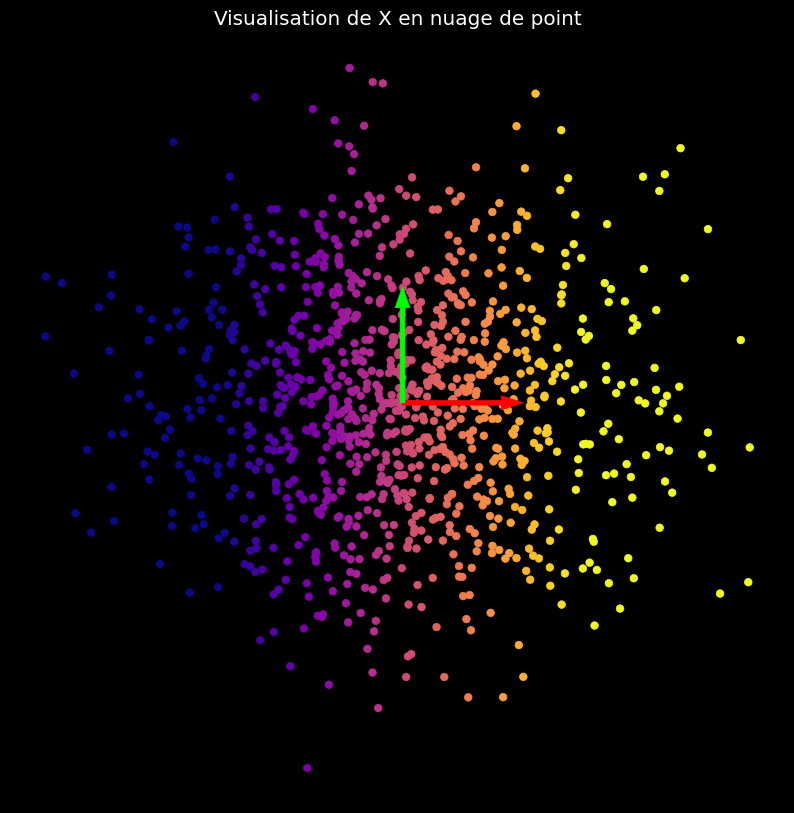

In [25]:
show_scatterplot(X,'Visualisation de X en nuage de point')
plot_bases(torch.tensor([[0., 0.], [0., 0.], [1., 0.], [0., 1.]])) # on a ajouté les origines et vecteurs directions des flèches rouge et verte

3. Explain briefly the Singular Value Decomposition (SVD). For a matrix $W$ of size $(n, m)$, give the shapes of $U$, $S$ and $V$, and the geometric meaning of each factor.

**Singular Value Decomposition** : Décompositon d'une matrice ($W$ = $U$ * $S$ * $V^T$), elle réduit la dimension d'un dataset pour garder les caractéristiques les plus importantes en conservant un max de données. 

- U matrice orthogonale, c'est les vecteurs propres de $W$*$W^T$ -> dimension : (n,n)

- S c'est les racines carrées des valeurs propres (≠ 0) de $W$*$W^T$, elle a les valeurs singulières sur sa diagonale et est complétée par des 0 -> dimension : (n,m)

- V c'est les vecteurs propres de $W^T$*$W$ -> dimension : (m,m)



4. Explain the relation between rotation and orthogonal matrices. Prove that an orthogonal matrix preserves the Euclidean norm of a vector.

Une matrice A est orthogonale si elle vérifie : $A^T$ $A$ = $A$ $A^T$ = $In$, car les colonnes d’une matrice orthogonale forment une base orthonormée : le coefficient $(i,j)$ du produit $A^T A$ est le produit scalaire de la colonne $i$ avec la colonne $j$, ce qui donne 1 sur la diagonale (norme unitaire) et 0 ailleurs (orthogonalité).

Donc on a $\det A=\pm1$

- $\det A=+1$ : $A$ est une **rotation** (en 2-D : $R_\theta=\begin{pmatrix}\cos\theta&-\sin\theta\\ \sin\theta&\cos\theta\end{pmatrix}$) ;
- $\det A=-1$ : $A$ est une **réflexion** (symétrie par rapport à une droite).

*Preuve de la conservation de la norme.* Montrons que pour tout vecteur $x$, $$\|Ax\|^2=\|x\|^2$$
En effet :
$$\|Ax\|^2=(Ax)^\top(Ax)=x^\top A^\top A\,x=x^\top x=\|x\|^2 .$$

5. Explain the relation between scaling and diagonal matrices.

Si l'on multiplie un vecteur $x = (x_1, x_2, \dots, x_n)^T$ par une matrice diagonale $D$ dont les coefficients diagonaux sont $\lambda_1, \lambda_2, \dots, \lambda_n$ alors, comme $D$ est diagonale, chaque composante $x_i$ du vecteur est multipliée uniquement par le scalaire correspondant $\lambda_i$

Donc :
- Si $\vert{}\lambda_i\vert{} > 1$, dilatation
- Si $\vert{}\lambda_i\vert{} < 1$, contraction
- Si $\lambda_i < 0$, inversion de sens

6. Draw **one** random matrix $W$ of size (2,2).

   a. Compute its SVD with `torch.linalg.svd` and check numerically (with `torch.allclose`) that $W = U \,\mathrm{diag}(S)\, V^T$.

   b. Apply successively to $X$ the three elementary transformations $V^T$, then $\mathrm{diag}(S)$, then $U$. Plot the 4 point clouds (original, after each step) and check that the last one is identical to $Y = XW^T$.

True


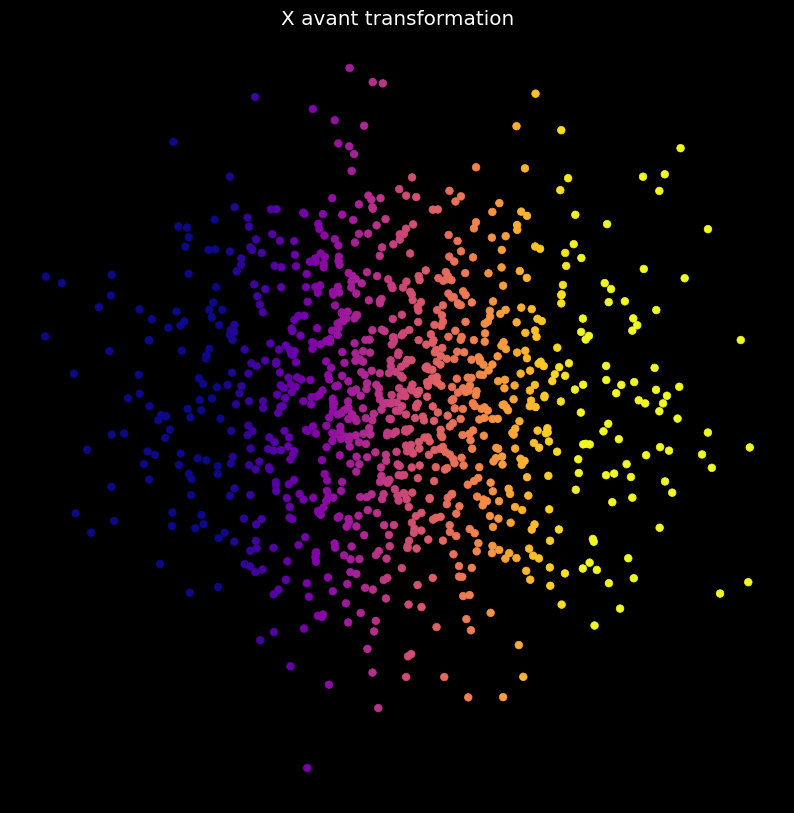

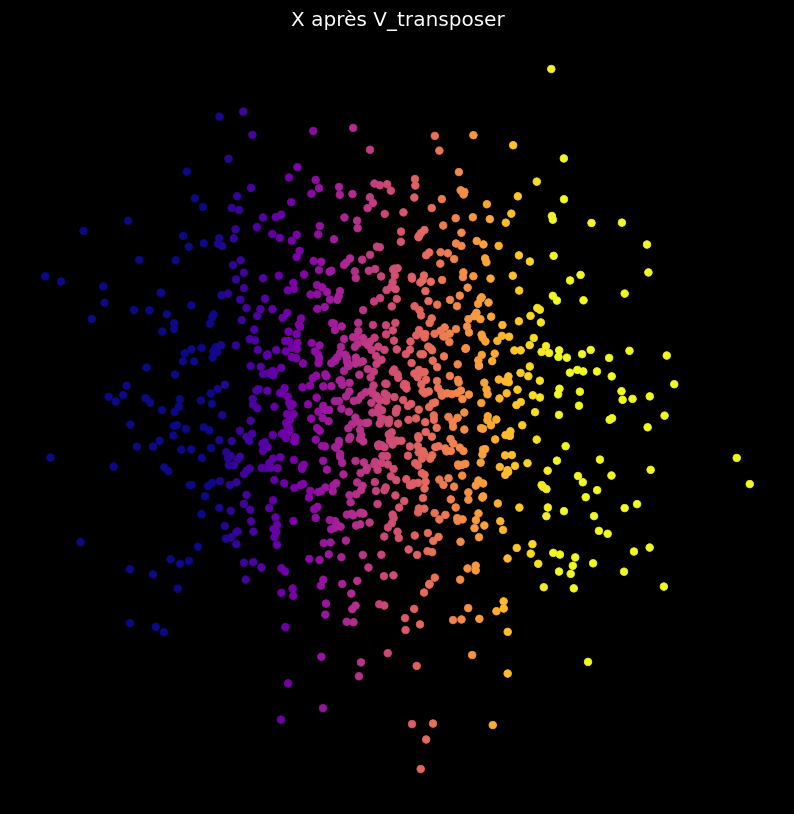

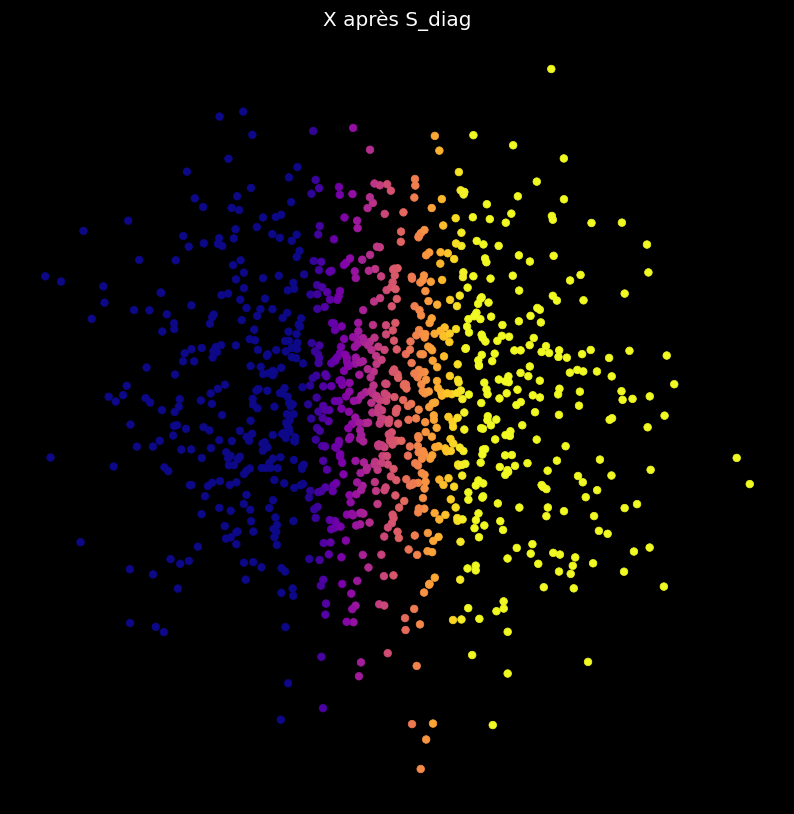

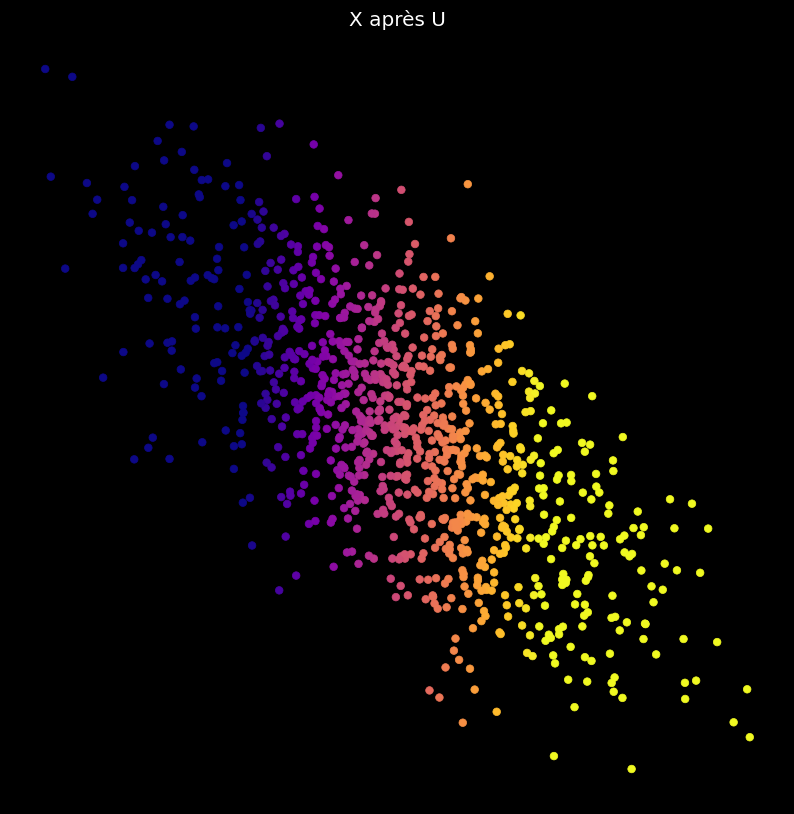

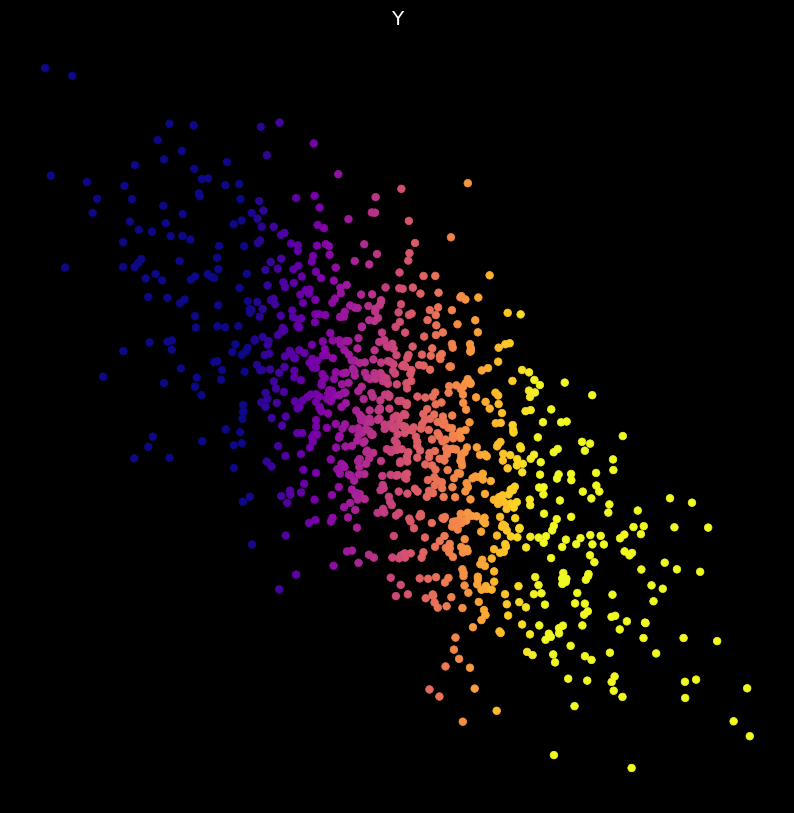

In [26]:
# a)
torch.manual_seed(20)
W = torch.randn(2,2,device=device)
U, S, V_transposer = torch.linalg.svd(W)
S_diag = torch.diag(S)

W_svd = U @ S_diag @ V_transposer
torch.allclose(W,W_svd)

# b) l'énoncé suppose qu’un point est un vecteur colonne x mais dans X, chaque point est une ligne, donc xᵀ d'où l'application de la transposée
show_scatterplot(X,'X avant transformation')
X1 = X @ V_transposer.T
show_scatterplot(X1,'X après V_transposer')
X2 = X1 @ S_diag
show_scatterplot(X2,'X après S_diag')
X3 = X2 @ U.T
show_scatterplot(X3,'X après U')

Y = X @ np.transpose(W)
show_scatterplot(Y,'Y')
print(torch.allclose(X3, Y, atol=1e-5)) # ça renvoyait false à cause de l'arrondi

7. Compute 10 linear transformations using several random matrices $W$ of size (2,2).

    For each transformation, compute the SVD of W, and visualize the transformed point cloud $Y$ with its corresponding singular values $(s_1,s_2)$ in the title.

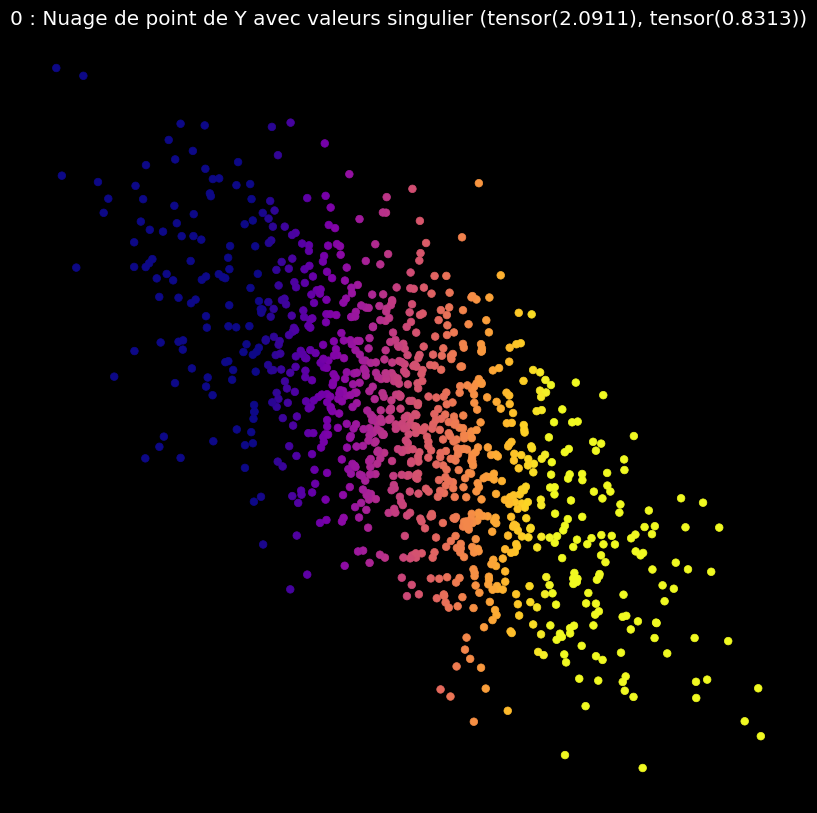

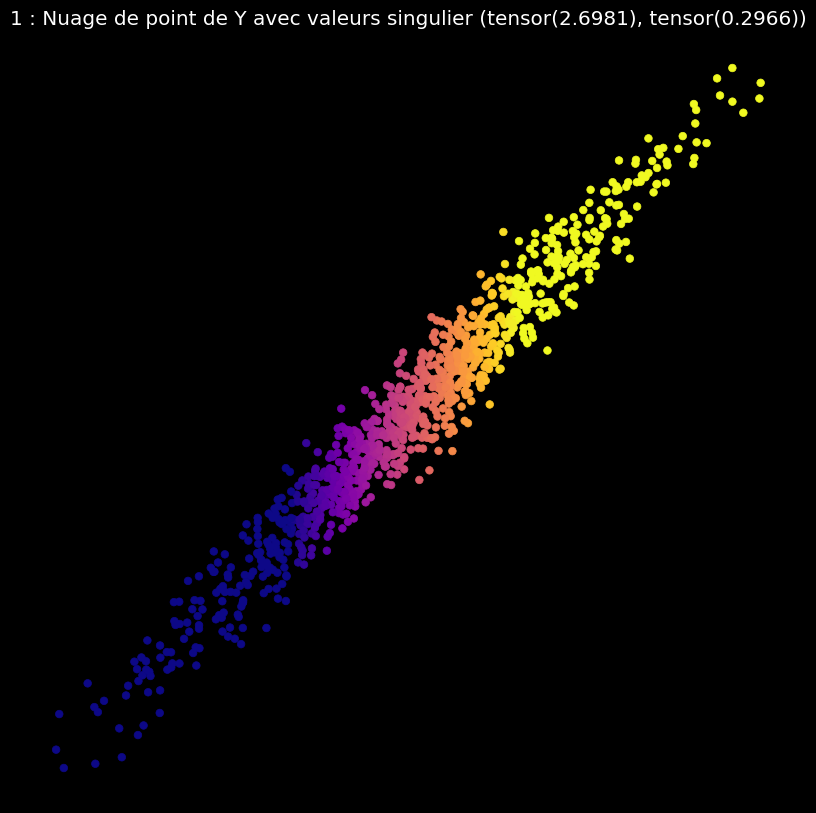

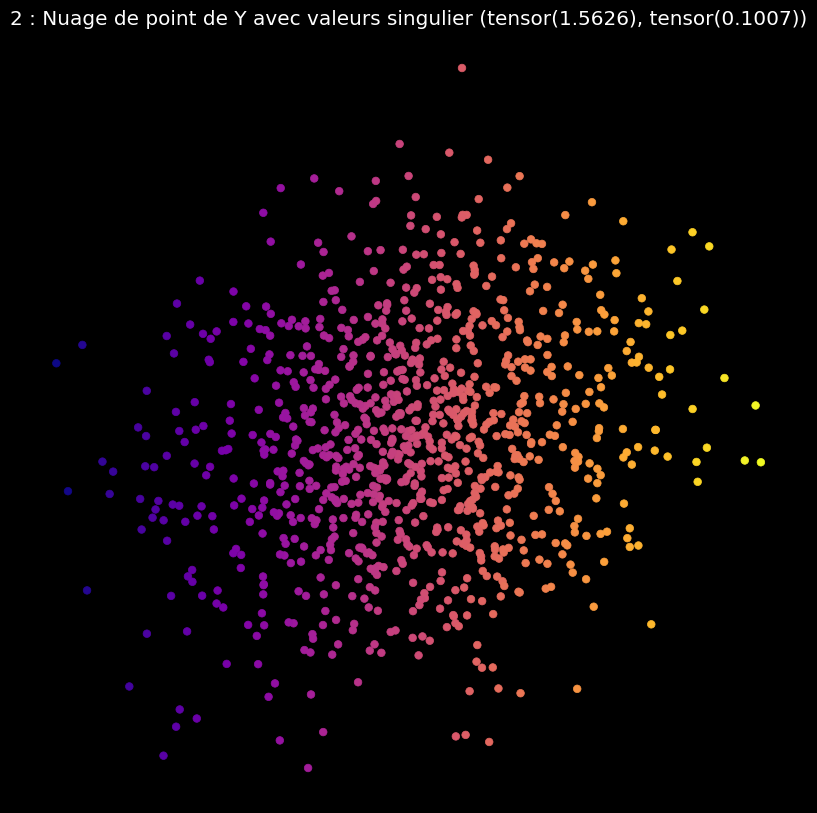

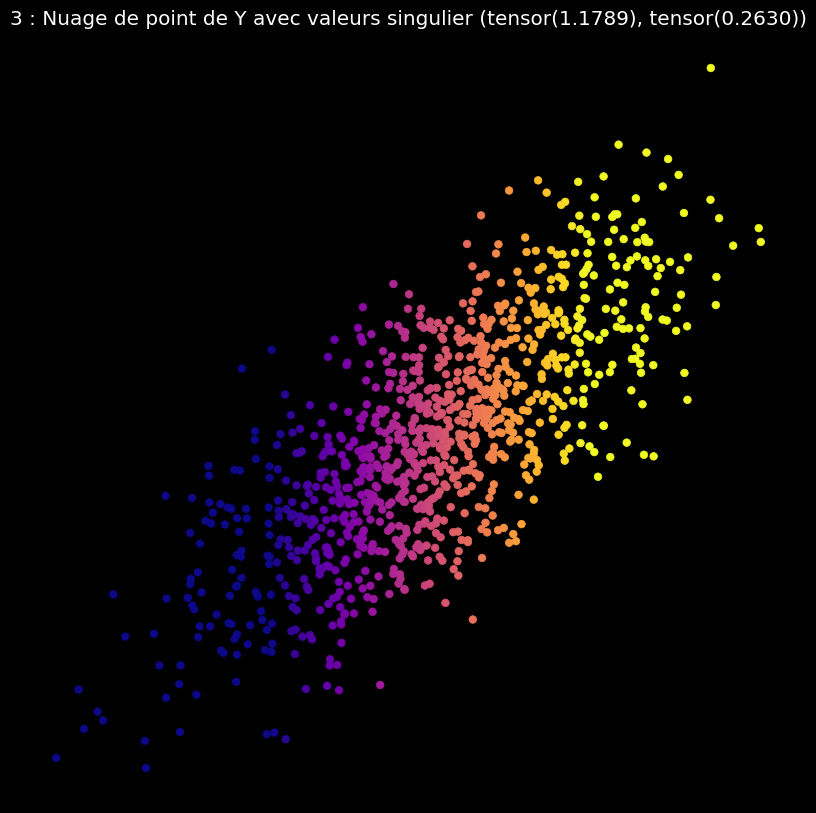

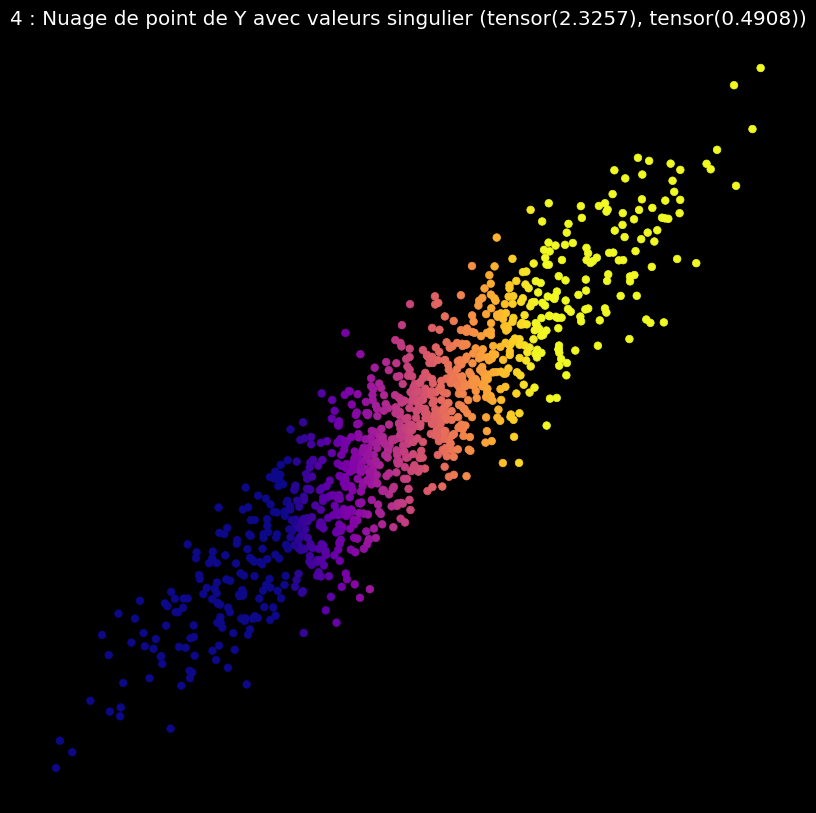

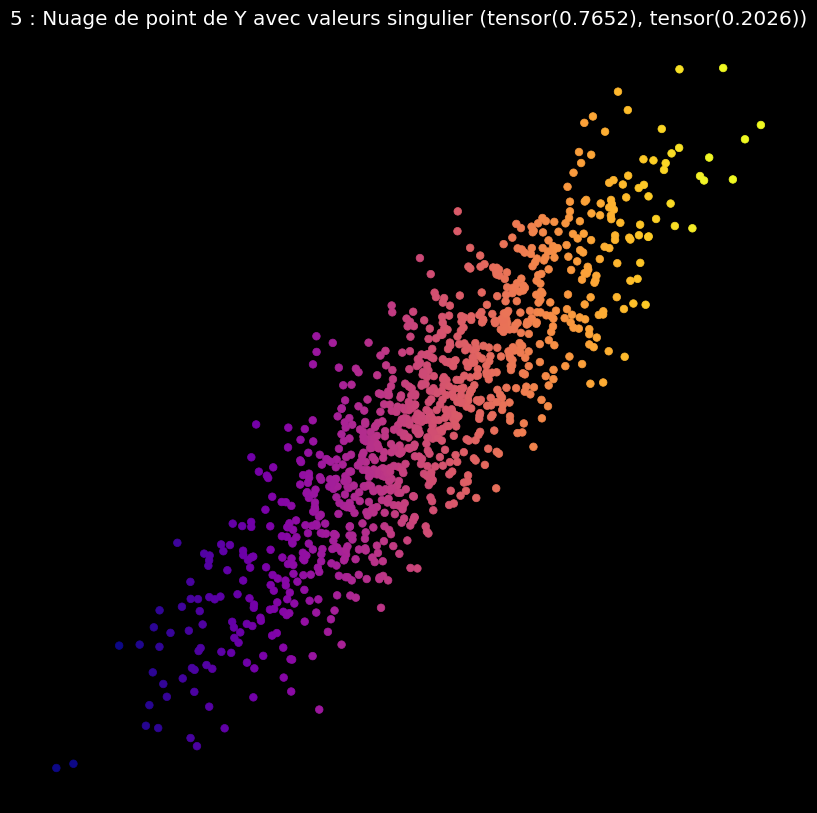

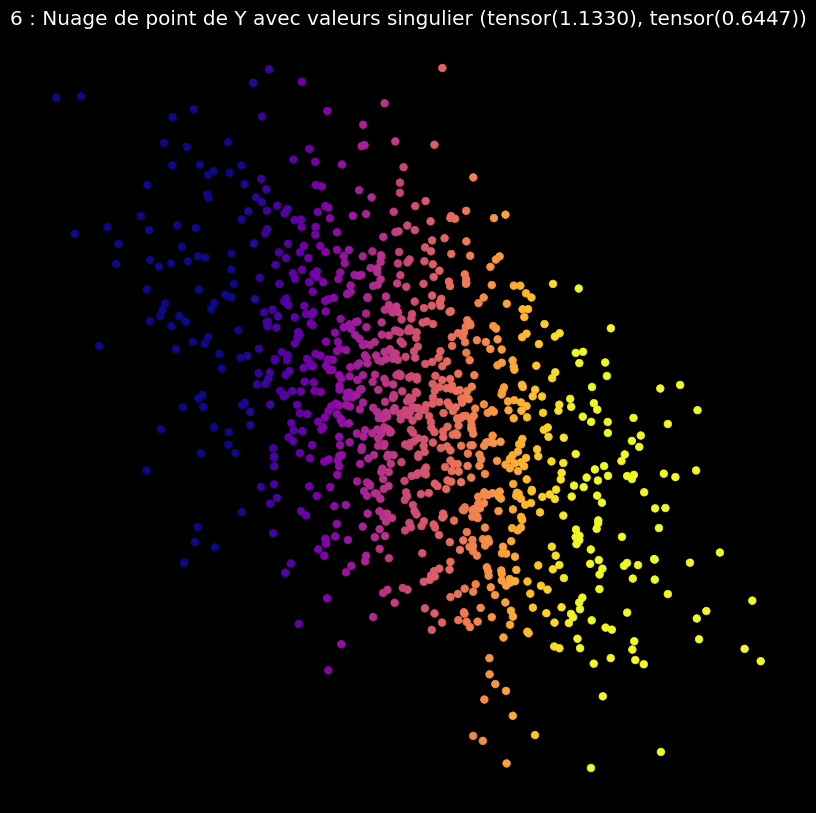

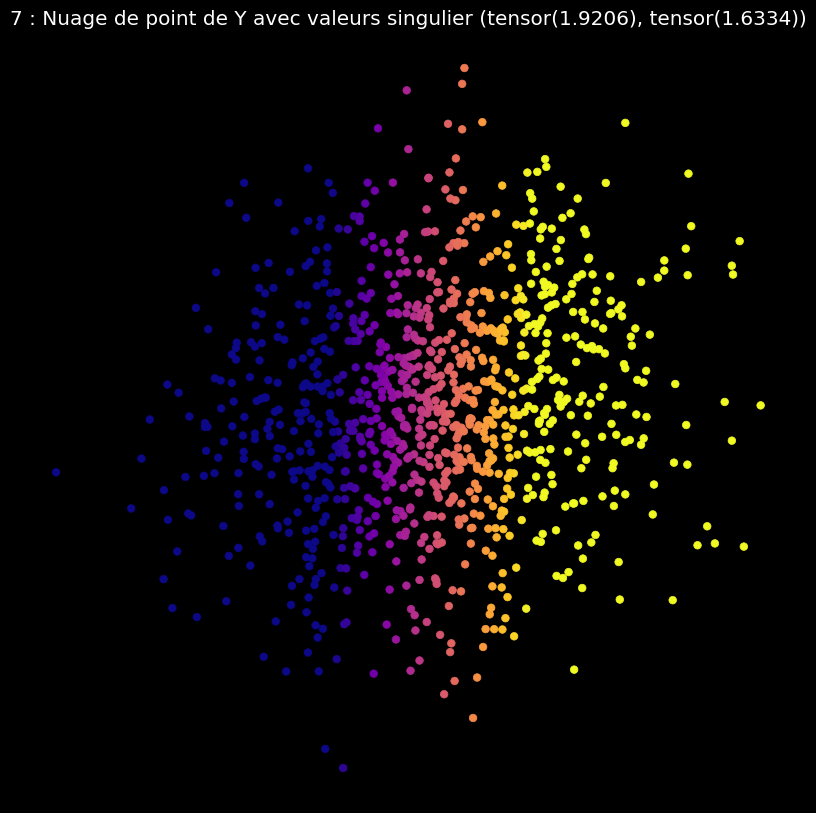

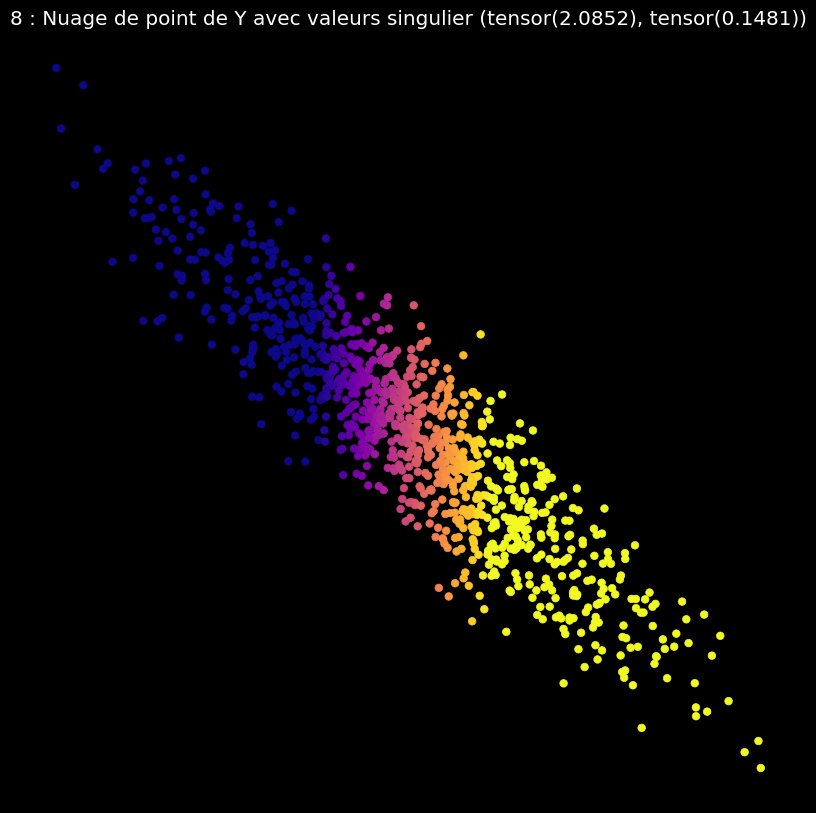

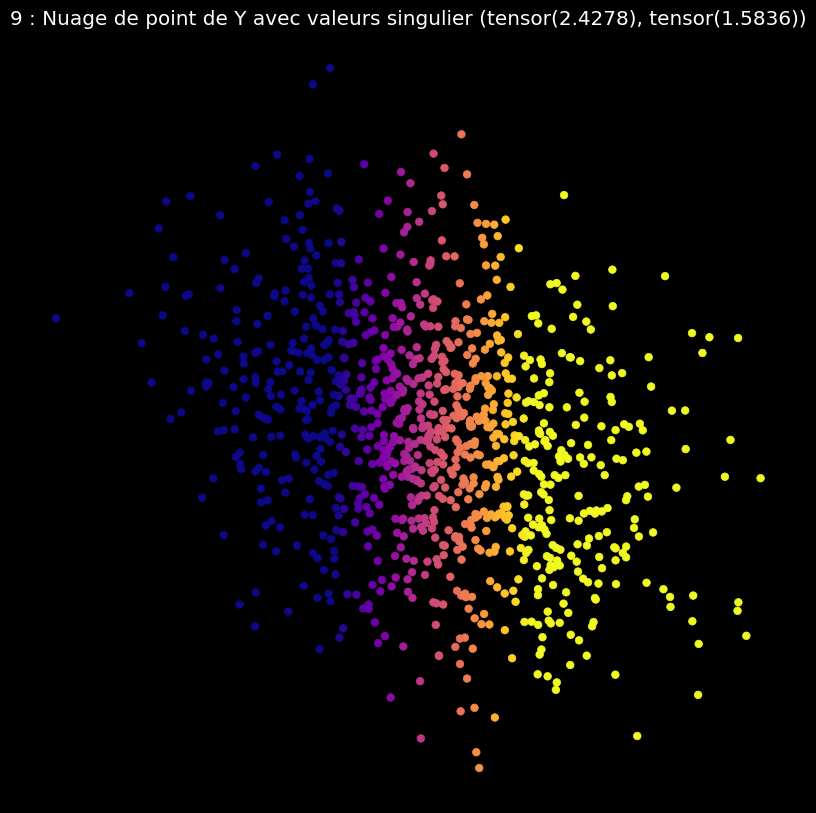

In [27]:
torch.manual_seed(20)
liste_W = []
liste_singular_value = []
for i in range(10):
    W = torch.randn(2,2,device=device)
    U, S, V_transposer = torch.linalg.svd(W)
    S_diag = torch.diag(S)
    
    Y_i = X @ np.transpose(W)
    show_scatterplot(Y_i,f'{i} : Nuage de point de Y avec valeurs singulier {S_diag[0][0],S_diag[1][1]}')
    liste_W.append(W)
    liste_singular_value.append((S_diag[0][0],S_diag[1][1]))

8. For each of the 10 matrices of question 7, compute $\det(W)$ and compare $|\det(W)|$ with $s_1 s_2$. What does $|\det(W)|$ represent geometrically? What happens to the point cloud when $\det(W) < 0$? And when $s_2$ is close to 0?

In [31]:
for i in range(len(liste_W)):
    det_W = np.linalg.det(liste_W[i])
    absolute_detW = np.abs(det_W)
    if det_W < 0 : 
        print(f"\nDETERMINANT :\t {i} : On a comme determinant : {det_W} et les valeurs singulières sont : {liste_singular_value[i]}")
    if liste_singular_value[i][1] < 0.2:
        print(f"\nS2 : {i} : On a s2 : {liste_singular_value[i][1]}")



S2 : 2 : On a s2 : 0.10067550837993622

DETERMINANT :	 4 : On a comme determinant : -1.1415417194366455 et les valeurs singulières sont : (tensor(2.3257), tensor(0.4908))

DETERMINANT :	 5 : On a comme determinant : -0.15501616895198822 et les valeurs singulières sont : (tensor(0.7652), tensor(0.2026))

S2 : 8 : On a s2 : 0.14806094765663147

DETERMINANT :	 9 : On a comme determinant : -3.844515562057495 et les valeurs singulières sont : (tensor(2.4278), tensor(1.5836))


9. Analyse the results of questions 7 and 8.

- question 7 : Le nuage initial $X$ est à peu près rond, après $Y = XW^\top$, il devient une **ellipse** : $V^\top$ le tourne, $\mathrm{diag}(S)$ l'étire puis $U$ le tourne une 2ème fois. Les axes de l'ellipse sont les directions de $U$. Avec s1, s2 les deux valeurs singulières de W, plus $s_1/s_2$ est grand, plus l'ellipse est allongée

- question 8 : On a $|\det W| = s_1 s_2$, car $|\det U|=|\det V|=1$ (matrices orthogonales). C'est bien ce qu'on observe : pour $i=4$, $2.3257\times0.4908$ = $0.1415=|\det W|$. (N.B. : l'aire de l'ellipse vaut $|\det W|$ fois celle du nuage de départ (dilatation si $>1$, contraction si $<1$))

# Linear transformation with PyTorch’s nn.Linear class.

10. Compute a similar linear transformation with PyTorch’s `nn.Linear` class:

    a. Set (without training) the weights of the layer to the matrix $W$ of question 6 and the bias to zero. Check that you obtain exactly the same point cloud as in question 6.

    b. Now set a non-zero bias. Visualize the result: which transformation is added?

True
True


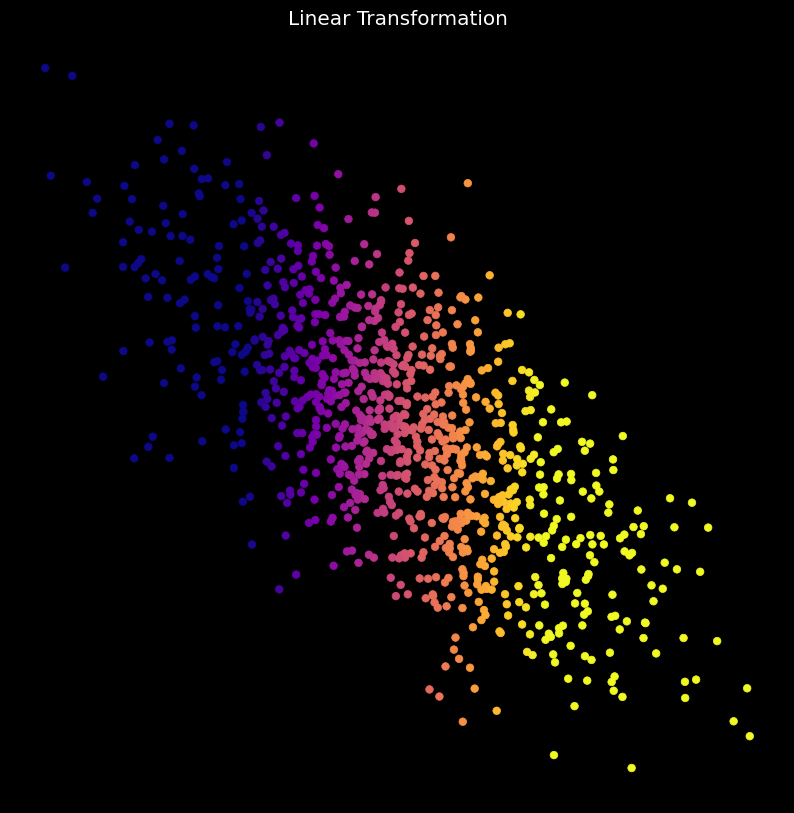

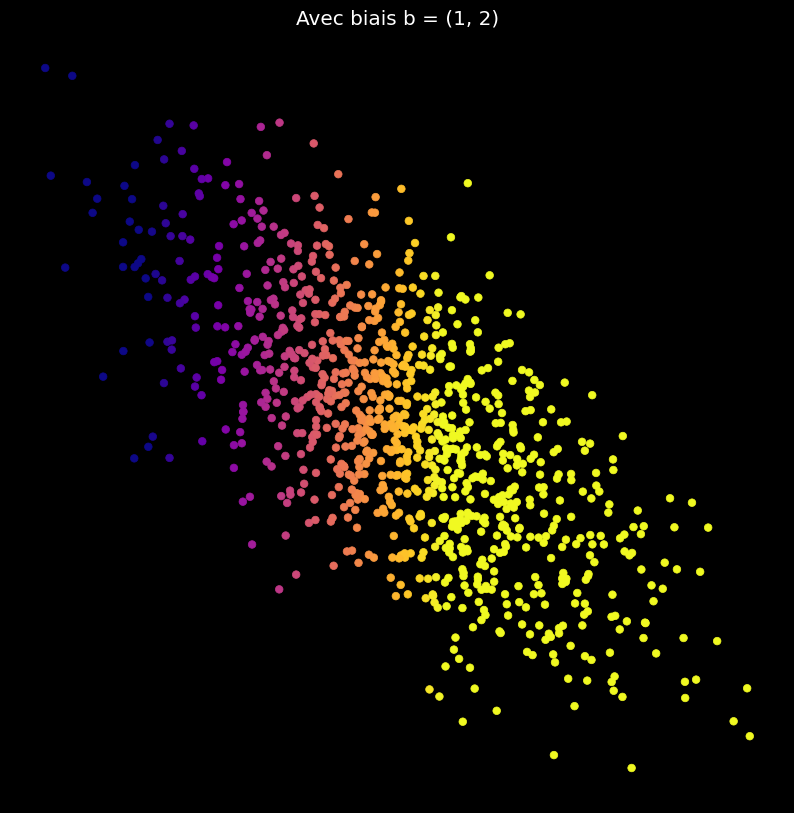

In [39]:
torch.manual_seed(20); W = torch.randn(2,2,device=device) # pcq W de la question 7 écrase de la 6
Y = X @ W.T

# a)
layer = nn.Linear(2, 2, bias=True).to(device)

with torch.no_grad():
    layer.weight.copy_(W)
    layer.bias.zero_()
    Y_linear = layer(X)

print(torch.allclose(Y_linear, Y, atol=1e-6))
show_scatterplot(Y_linear,"Linear Transformation")

# b)
with torch.no_grad():
    layer.bias.copy_(torch.tensor([1., 2.]))
Y_bias = layer(X).detach()
show_scatterplot(Y_bias, "Avec biais b = (1, 2)")
print(torch.allclose(Y_bias, Y + torch.tensor([1., 2.], device=device), atol=1e-5))


# Non-linear transformations

11. Plot the graph of the hyperbolic tangent function (tanh). What do you notice about it ?

Text(0.5, 1.0, 'tanh')

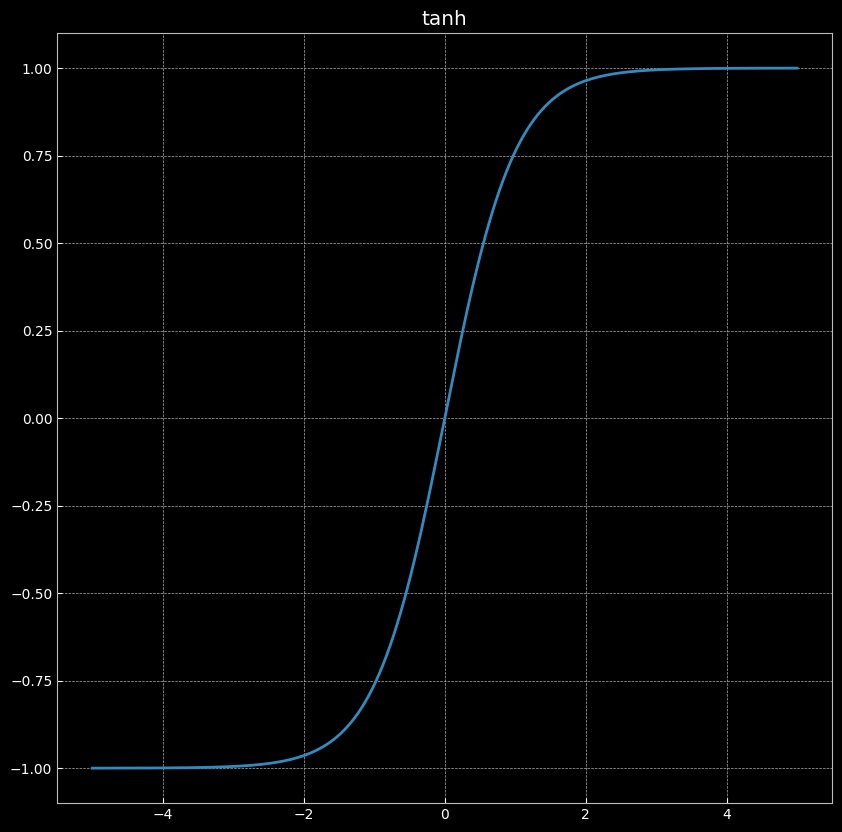

In [40]:
x = torch.linspace(-5, 5, 200)
plot(x, torch.tanh(x))
title("tanh")

observations :
- une courbe en **S**, strictement croissante, impaire ($\tanh(-z)=-\tanh z$), qui passe par l'origine ;
- elle est bornée : ses valeurs restent dans $]-1,1[$ ;
- près de 0 elle est presque la droite $y=z$

12. For s=1,...,5.
    Compute a linear transformation with PyTorch’s nn.Linear class (the transformation matrix must be a $2*2$ diagonal matrix, with diagonal elements all equal to s), followed by a non-linear transformation using tanh. Visualise the results.

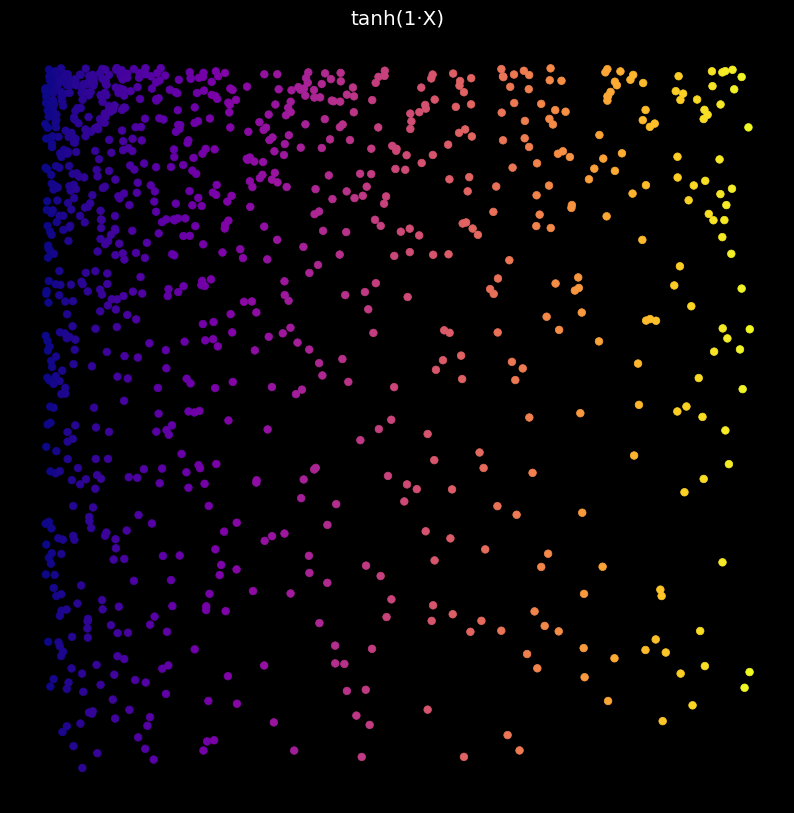

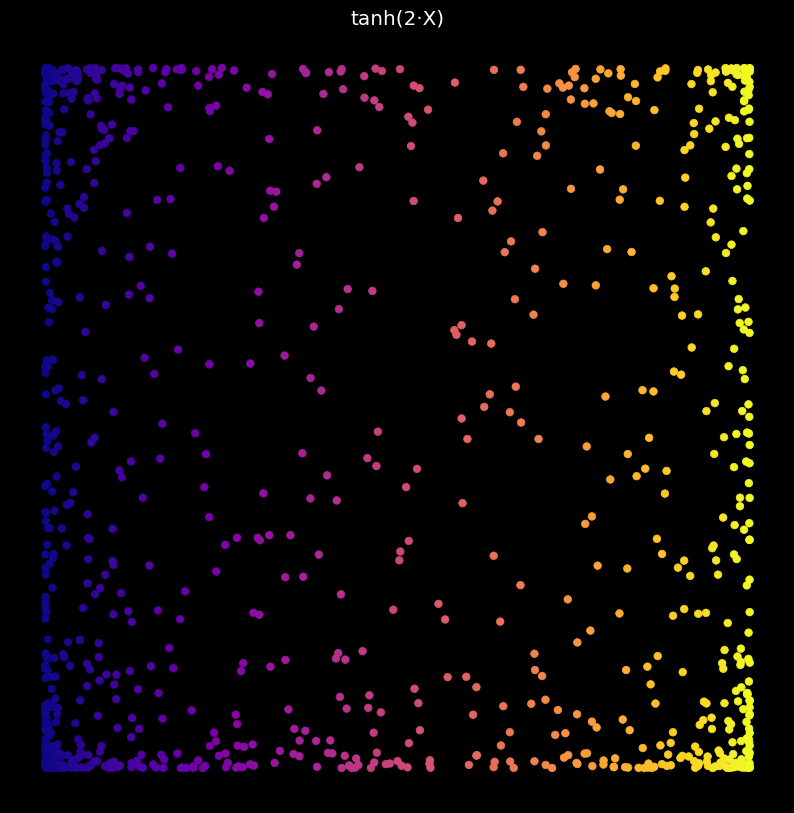

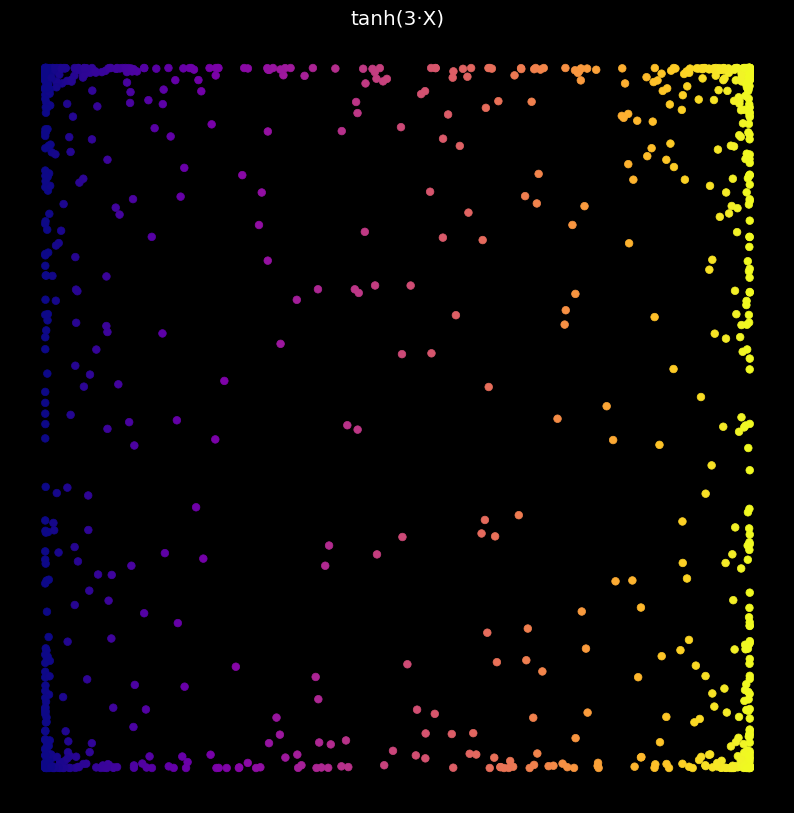

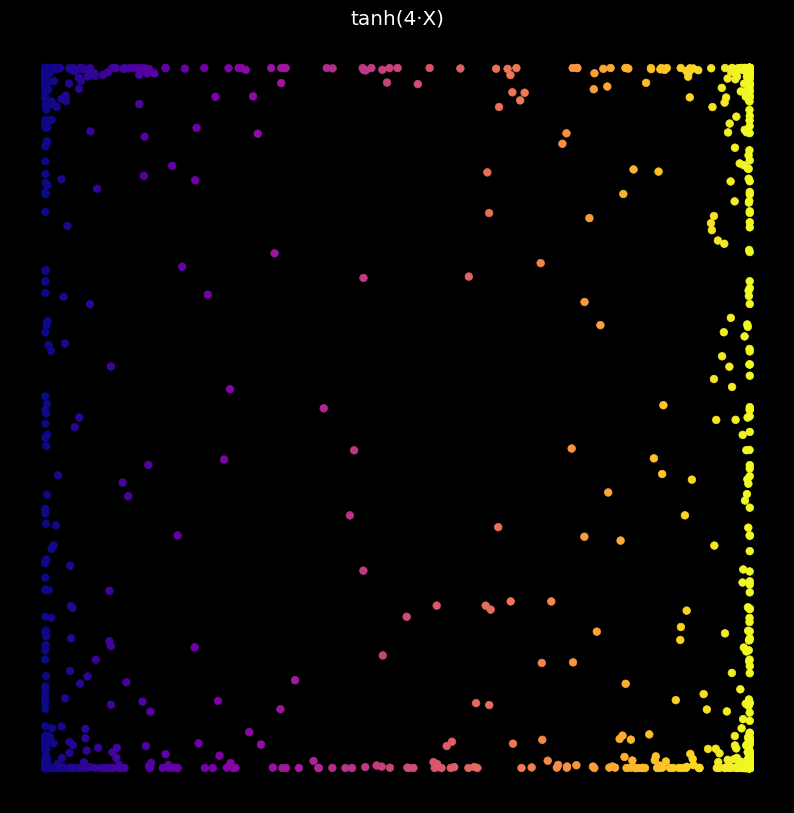

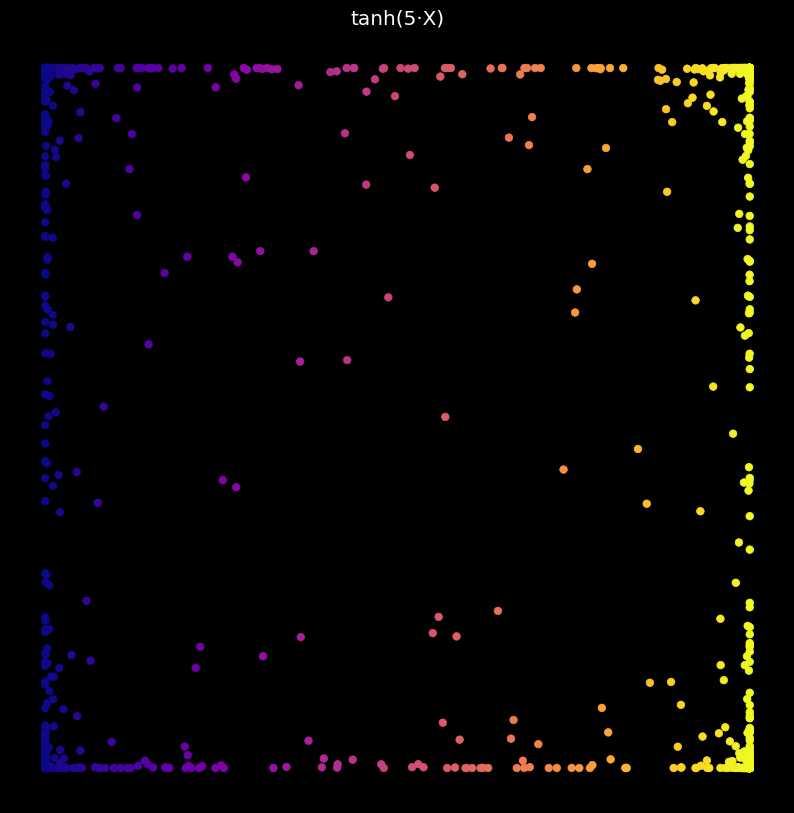

In [44]:
for s in range(1, 6):
    layer = nn.Linear(2, 2, bias=True).to(device)

    with torch.no_grad():
        layer.weight.copy_(torch.eye(2) * s) # torch.eye(2) c'est matrice identité 2x2 donc on a juste une matrice diag avec s en diag
        Y_s = torch.tanh(layer(X))

    show_scatterplot(Y_s.cpu(), f"tanh({s}·X)")

13. Analyse the results. Then redo the experiment for $s = 3$ only, replacing tanh by `sigmoid` and then by `ReLU`. Describe and explain the differences between the three point clouds.

# Transformations performed by a random neural net

14. Compute the network transformation consisting of a linear layer (2 → 5), which performs an affine transformation, followed by a hyperbolic tangent non-linearity, and finally another linear layer (5 → 2). Visualize the transformed point cloud.

15. Answer the above question using a deeper neural network (for instance 5 hidden layers of width 100). Run it several times with different random initializations and comment.

16. a. Repeat question 15 with `ReLU` instead of tanh. What kind of shapes do you observe in the transformed cloud?

    b. Remove all non-linearities from the deep network. Show (by a short computation for 2 layers, then by an experiment) that the network is then equivalent to a single affine transformation, whatever its depth. Conclude on the role of non-linearities.